# Liveness data preparation and audit

This notebook inspects or audits the frozen post-review selection: 444,114 train, 49,479 validation and 67,129 test images. It preserves source images, labels, original splits, exclusions and checkpoints. Inspect is the default and reads saved counts/previews without the full dataset.

<details>
<summary>Local execution</summary>

With the [project environment](../docs/setup.md) active, run from the repository root:

```sh
python scripts/run_liveness_notebook.py --notebook notebooks/liveness-data-preparation-and-audit.ipynb --action inspect
```

Use `--action audit` only when the complete extracted dataset is available. It verifies every retained image/box and saves a new report; it does not change selection.

</details>

<details>
<summary>Google Colab execution</summary>

Set shared project/archive folder IDs and ACTION. Audit needs a fresh Python 3.13 CPU runtime, all 74 archive parts and at least 85 GiB free VM disk plus Drive caching overhead. It restores frozen metadata rather than selecting subjects again. Commenters write new outputs to private MyDrive. Native revised Colab execution remains unverified.

</details>

[Review criteria and historical evidence](../docs/liveness-data-preparation-and-audit.md) explain the exclusions. Source integrity does not establish complete semantic correctness or source-video independence.


## 1\. Connect Drive and verify project source

Resolve shared inputs by folder ID, select a writable output destination and validate the release inventory before loading project code.

In [ ]:
import hashlib
import json
import os
import shutil
import subprocess
import sys
import time
import venv
from datetime import UTC, datetime
from pathlib import Path
from urllib.parse import urlparse

In [ ]:
IS_COLAB = sys.modules.get("google.colab") is not None
if IS_COLAB:
    from IPython.display import HTML, display
else:
    LOCAL_PROJECT = Path(globals().get("LOCAL_PROJECT", Path.cwd())).resolve()
    if LOCAL_PROJECT.name == "notebooks":
        LOCAL_PROJECT = LOCAL_PROJECT.parent
    sys.path.insert(0, str(LOCAL_PROJECT / "src"))
    from facial_attendance.notebook_runtime import HTML, display

Set the project folder URL/ID below. The archive folder is required only for a new Colab audit; inspect uses saved evidence without opening the archive. Project access does not grant archive access.


In [ ]:
PROJECT_FOLDER = (
    "https://drive.google.com/drive/folders/1JSB858oMc2k9uaO1o8ZNma32zTySe1dC"
)
ARCHIVE_FOLDER = (
    "https://drive.google.com/drive/folders/1OW_1bawO79pRqdVEVmBzp8HSxdSwln_Z"
)
ACTION = globals().get("ACTION", "inspect")
if ACTION not in ("inspect", "audit"):
    raise ValueError("Select inspect or audit")

Accept the shared project folder URL or its ID. Notebook URLs are rejected so copying a notebook cannot silently select a different project.

In [ ]:
def drive_folder_id(value):
    "Accept a folder URL/ID without inferring location from a notebook."
    parsed = urlparse(value.strip())
    identifier = value.strip()
    if parsed.scheme or parsed.netloc:
        if parsed.scheme != "https" or parsed.netloc != "drive.google.com":
            raise ValueError("Supply a Google Drive folder URL or folder ID")
        parts = parsed.path.rstrip("/").split("/")
        if len(parts) < 2 or parts[-2] != "folders":
            raise ValueError("Use the project folder URL, not a notebook URL")
        identifier = parts[-1]
    if not identifier or any(
        c not in "abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789_-"
        for c in identifier
    ):
        raise ValueError("Invalid Google Drive folder ID")
    return identifier

Folder and shortcut searches read every API page. Identity comes from IDs; folder names alone do not identify a project.

In [ ]:
def drive_items(api, query):
    "Read every page so shortcut reuse does not depend on listing order."
    items, token = [], None
    while True:
        page = (
            api.files()
            .list(
                q="trashed=false and " + query,
                pageToken=token,
                fields="nextPageToken,files(id,name,parents,mimeType,shortcutDetails)",
                supportsAllDrives=True,
                includeItemsFromAllDrives=True,
            )
            .execute()
        )
        items.extend(page.get("files", []))
        token = page.get("nextPageToken")
        if not token:
            return items


def named_children(api, parent, name):
    "Escape Drive query syntax for names containing quotes or backslashes."
    escaped = name.replace("\\", "\\\\").replace("'", "\\'")
    return drive_items(api, f"'{parent}' in parents and name='{escaped}'")

Check access to the folder before mounting. A missing folder or denied access receives a readable message; quota and server errors retain their original cause.

In [ ]:
if IS_COLAB:
    from googleapiclient.errors import HttpError


def drive_access_denied(error):
    "Keep quota/server failures distinct from inaccessible file IDs."
    if error.resp.status == 404:
        return True
    try:
        details = json.loads(error.content).get("error", {}).get("errors", [])
    except (TypeError, ValueError):
        return False
    reasons = {row.get("reason") for row in details}
    return error.resp.status == 403 and bool(
        reasons & {"insufficientFilePermissions", "appNotAuthorizedToFile"}
    )

Read folder metadata using the verified ID. Access errors identify the folder/account checks to make; other API failures remain visible.

In [ ]:
def drive_folder_metadata(api, folder_id):
    "Read folder capabilities without creating a writable probe."
    try:
        item = (
            api.files()
            .get(
                fileId=folder_id,
                fields="id,name,mimeType,parents,capabilities(canAddChildren)",
                supportsAllDrives=True,
            )
            .execute()
        )
    except HttpError as error:
        if drive_access_denied(error):
            raise PermissionError(
                "Folder unavailable: check its URL, the signed-in account and folder sharing permissions."
            ) from error
        raise
    if item.get("mimeType") != "application/vnd.google-apps.folder":
        raise ValueError("The supplied ID must identify a folder")
    return item

Follow accessible parent folders to MyDrive. Ambiguous or unsafe path components use an ID-based shortcut instead; the owner’s private ancestors are not required.

In [ ]:
def my_drive_folder_path(api, folder_id, root_id):
    "Return an unambiguous path within this account's MyDrive, if any."
    names, visited = [], set()
    while folder_id != root_id:
        if folder_id in visited:
            raise ValueError("Drive folder ancestry contains a cycle")
        visited.add(folder_id)
        try:
            item = (
                api.files()
                .get(fileId=folder_id, fields="id,name,parents", supportsAllDrives=True)
                .execute()
            )
        except HttpError as error:
            if drive_access_denied(error):
                return None
            raise
        name, parents = item["name"], item.get("parents", [])
        if name in ("", ".", "..") or "/" in name or len(parents) != 1:
            return None
        if len(named_children(api, parents[0], name)) != 1:
            return None
        names.append(name)
        folder_id = parents[0]
    return tuple(reversed(names))

Reuse an existing shortcut even when it is inside a MyDrive subfolder. Create a new shortcut only when neither a direct path nor an accessible shortcut exists.

In [ ]:
def drive_shortcut_path(api, folder_id, root_id):
    "Reuse by target ID, including shortcuts nested inside MyDrive."
    query = "mimeType='application/vnd.google-apps.shortcut' and shortcutDetails.targetMimeType='application/vnd.google-apps.folder'"
    for item in drive_items(api, query):
        if item.get("shortcutDetails", {}).get("targetId") == folder_id:
            path = my_drive_folder_path(api, item["id"], root_id)
            if path is not None:
                return path
    alias, number = "colab-folder-" + folder_id, 0
    while named_children(api, root_id, alias):
        number += 1
        alias = f"colab-folder-{folder_id}-{number}"
    api.files().create(
        body={
            "name": alias,
            "mimeType": "application/vnd.google-apps.shortcut",
            "parents": [root_id],
            "shortcutDetails": {"targetId": folder_id},
        },
        fields="id",
    ).execute()
    return (alias,)

Combine folder validation and path selection. Reuse a direct MyDrive path first, then a matching shortcut.

In [ ]:
def resolve_drive_folder(api, value, root_id):
    "Validate the folder before selecting a direct path or shortcut."
    item = drive_folder_metadata(api, drive_folder_id(value))
    path = my_drive_folder_path(api, item["id"], root_id)
    return item, path if path is not None else drive_shortcut_path(
        api, item["id"], root_id
    )

Commenters and viewers write to their own MyDrive/facial-attendance-outputs, separated by project ID. Existing output folders must be unambiguous and writable; no probe files are created.

In [ ]:
def ensure_output_folder(api, parent, name):
    "Create a personal output folder or verify its ability to accept files."
    matches = named_children(api, parent, name)
    if len(matches) > 1:
        raise ValueError(f"Output folder name is ambiguous: {name}")
    if matches:
        item = drive_folder_metadata(api, matches[0]["id"])
    else:
        item = (
            api.files()
            .create(
                body={
                    "name": name,
                    "mimeType": "application/vnd.google-apps.folder",
                    "parents": [parent],
                },
                fields="id,capabilities(canAddChildren)",
            )
            .execute()
        )
    if not item.get("capabilities", {}).get("canAddChildren", False):
        raise PermissionError(f"Cannot create outputs in {name}")
    return item["id"]

Use the shared project only when its existing evidence folders allow new files. Otherwise select a private output folder, leaving source code, checkpoints and shared evidence unchanged.

In [ ]:
def output_project_id(api, project, root_id, evidence_parts=("evidence", "liveness")):
    "Use private outputs when the evidence destination is not writable."
    current, writable = project, True
    for name in evidence_parts:
        writable = current.get("capabilities", {}).get("canAddChildren", False)
        if not writable:
            break
        matches = named_children(api, current["id"], name)
        if not matches:
            return project["id"]
        if len(matches) != 1:
            raise ValueError(f"Evidence folder name is ambiguous: {name}")
        current = drive_folder_metadata(api, matches[0]["id"])
    if writable and current.get("capabilities", {}).get("canAddChildren", False):
        return project["id"]
    parent = ensure_output_folder(api, root_id, "facial-attendance-outputs")
    return ensure_output_folder(api, parent, project["id"])

Drive API setup happens before mounting. Allow up to 30 seconds for each folder to become visible; an existing mount is not forcibly replaced while another operation may be using it.

In [ ]:
def wait_for_drive_folder(path):
    "Bound DriveFS propagation waits without disrupting mounted jobs."
    deadline = time.monotonic() + 30
    while time.monotonic() < deadline:
        if path.is_dir():
            return path
        time.sleep(1)
    raise FileNotFoundError(
        "Drive folder is not visible yet. Reconnect Drive and rerun setup; existing files are retained."
    )

Authenticate with the account receiving the shared project. Resolve its folder ID and output destination through the API, then mount Drive and confirm the paths are readable.

In [ ]:
if IS_COLAB:
    from google.colab import auth, drive
    from googleapiclient.discovery import build

    # No project module is needed to locate the shared inputs or private outputs.
    auth.authenticate_user()
    drive_api = build("drive", "v3", cache_discovery=False)
    root_id = drive_api.files().get(fileId="root", fields="id").execute()["id"]
    project_metadata, project_parts = resolve_drive_folder(
        drive_api, PROJECT_FOLDER, root_id
    )
    output_id = output_project_id(
        drive_api,
        project_metadata,
        root_id,
        evidence_parts=("evidence", "runs", "LIV-03", "colab"),
    )
    output_parts = my_drive_folder_path(drive_api, output_id, root_id)
    if ACTION == "audit":
        _, archive_parts = resolve_drive_folder(drive_api, ARCHIVE_FOLDER, root_id)
    drive.mount("/content/drive")
    drive_root = Path("/content/drive/MyDrive")
    DRIVE_PROJECT = wait_for_drive_folder(drive_root.joinpath(*project_parts))
    OUTPUT_PROJECT = wait_for_drive_folder(drive_root.joinpath(*output_parts))
    if ACTION == "audit":
        archive = wait_for_drive_folder(drive_root.joinpath(*archive_parts))
else:
    DRIVE_PROJECT = LOCAL_PROJECT
    OUTPUT_PROJECT = LOCAL_PROJECT

The Colab route validates the selected project layout and release before loading project source. Local execution uses the activated environment and the source in the project working directory.

In [ ]:
def load_project_release(project):
    "Reject missing layout or unsafe inventory before loading project code."
    required = ("src", "scripts", "configs")
    if not all((project / name).is_dir() for name in required):
        raise FileNotFoundError("Project needs src, scripts and configs folders")
    path = project / "configs/liveness-release.json"
    release = json.loads(path.read_text(encoding="utf-8"))
    if (
        release.get("schema") != "liveness-training-release-v1"
        or not isinstance(release.get("files"), dict)
        or not release["files"]
    ):
        raise ValueError("Unsupported or empty project release inventory")
    for name, record in release["files"].items():
        for relative in (name, record["delivery_path"]):
            if not (project / relative).resolve().is_relative_to(project.resolve()):
                raise ValueError("Release path escapes the project")
        if len(record["sha256"]) != 64 or any(
            c not in "0123456789abcdef" for c in record["sha256"]
        ):
            raise ValueError("Invalid release checksum")
    return release

Check each executable source file against its release checksum before staging it. Canonical paths must stay inside the selected project.

In [ ]:
def verified_source(project, record):
    "Verify declared source bytes inside the canonical project root."
    path = (project / record["delivery_path"]).resolve()
    if not path.is_relative_to(project.resolve()):
        raise ValueError("Source path escapes the project")
    content = path.read_bytes()
    if hashlib.sha256(content).hexdigest() != record["sha256"]:
        raise ValueError(f"Source checksum mismatch: {path.name}")
    return content

Validate the shared release before staging executable code. The runtime working directory is separate from Drive and must be new for an extraction run.

In [ ]:
release = load_project_release(DRIVE_PROJECT)
drive_project = DRIVE_PROJECT
repo = Path("/content/facial-attendance") if IS_COLAB else LOCAL_PROJECT
data = repo / "data/raw/liveness/celeba-spoof-full"
if sys.version_info[:2] != (3, 13):
    raise RuntimeError("Select the project's Python 3.13 runtime")
if IS_COLAB and ACTION == "audit":
    if repo.exists():
        raise FileExistsError("Start in a fresh runtime; existing source is preserved")
    repo.mkdir()

## 2. Frozen selection evidence

Inspect reads saved evidence from the current selection. Its previews cover one retained image per available source type in each split. Checksums bind the report to the frozen cache view and displayed images; preview inspection does not verify all retained files or unseen crop semantics.


In [ ]:
if ACTION == "inspect":
    evidence_name = release["crop_review"]["selection_inspection"]
    selection_report = json.loads(
        verified_source(DRIVE_PROJECT, release["files"][evidence_name])
    )
    view_name = release["crop_review"]["cache_view"]
    view_bytes = verified_source(DRIVE_PROJECT, release["files"][view_name])
    if selection_report["cache_view_sha256"] != hashlib.sha256(view_bytes).hexdigest():
        raise ValueError("Saved inspection belongs to another frozen selection")
    if not selection_report["completed"] or selection_report["mode"] != "inspect":
        raise ValueError("Expected a completed saved selection inspection")
    frozen_view = json.loads(view_bytes)
    for split, record in selection_report["splits"].items():
        for field in (
            "base_samples",
            "retained_samples",
            "quarantined_samples",
            "pending_review",
        ):
            if record[field] != frozen_view["splits"][split][field]:
                raise ValueError("Saved counts differ from the frozen selection")
    preview_root = Path(evidence_name).parent.as_posix()
    print("Saved inspection:", selection_report["created_at"])
    print(
        "Scope: frozen metadata and preview inputs; not a full image-integrity audit."
    )

Saved inspection: 2026-11-27T15:42:40.538156+00:00
Scope: frozen metadata and preview inputs; not a full image-integrity audit.


Colab verifies the frozen inventory, annotations and exclusion files before installation or extraction. A missing or changed input stops the run before the archive is processed.


In [ ]:
if IS_COLAB and ACTION == "audit":
    view_name = release["crop_review"]["cache_view"]
    view_parent = Path(view_name).parent.as_posix() + "/"
    data_prefix = "data/raw/liveness/celeba-spoof-full/"
    metadata_names = [
        data_prefix + "audits/current-schema-2026-11-12/inventory.csv",
        data_prefix + "reviewed_project_train.json",
        data_prefix + "project_validation.json",
        data_prefix + "metas/intra_test/test_label.json",
    ]
    metadata_names += [
        name for name in release["files"] if name.startswith(view_parent)
    ]
    for name in metadata_names:
        verified_source(DRIVE_PROJECT, release["files"][name])
    print("Frozen selection inputs verified before extraction.")

Select runtime modules, notebook fixtures and dependency/configuration files from the release allowlist. Dataset archives and credentials are excluded.

In [ ]:
if IS_COLAB and ACTION == "audit":
    source_files = [
        name
        for name in release["submission"]["source_files"]
        if name
        in (
            ".python-version",
            "requirements-cpu.txt",
            "requirements.txt",
            "requirements-cuda.txt",
            "requirements.lock",
            "pyproject.toml",
        )
        or (
            name.startswith(("src/", "scripts/", "tests/", "configs/", "notebooks/"))
            and Path(name).suffix in (".py", ".toml", ".ipynb")
        )
    ]

Verify and copy the allowlisted runtime files. Notebook snapshots remain editable fixtures; executable modules and configuration use release checksums.

In [ ]:
if IS_COLAB and ACTION == "audit":
    source_hashes = {}
    for name in source_files:
        record = release["files"][name]
        # Notebooks are editable entry points and fixtures, not imported training code.
        content = (
            (drive_project / name).read_bytes()
            if name.endswith(".ipynb")
            else verified_source(drive_project, record)
        )
        destination = repo / name
        destination.parent.mkdir(parents=True, exist_ok=True)
        destination.write_bytes(content)
        source_hashes[name] = hashlib.sha256(content).hexdigest()
    shutil.copy2(
        drive_project / "configs/liveness-release.json",
        repo / "configs/liveness-release.json",
    )

Create a uniquely named audit run in the selected writable destination and retain the exact hashes of the staged source.

In [ ]:
if IS_COLAB and ACTION == "audit":
    run_name = "reviewed-colab-" + datetime.now(UTC).strftime("%Y%m%dT%H%M%S%fZ")
    review = repo / "evidence/runs/LIV-03/colab" / run_name
    saved = OUTPUT_PROJECT / "evidence/runs/LIV-03/colab" / run_name
    review.mkdir(parents=True)
    saved.mkdir(parents=True, exist_ok=False)
    (review / "source-upload.json").write_text(json.dumps(source_hashes, indent=2))
    print("Project: facial-attendance")
    print("Run:", run_name)

## 3. Install the isolated CPU environment

Project packages are installed into the VM project environment; the notebook kernel retains its own packages. Every project command uses the isolated interpreter. Logs and completed outputs are copied to Drive, including when a command fails.

In [ ]:
if IS_COLAB and ACTION == "audit":
    python = repo / ".venv/bin/python"
    venv.EnvBuilder(with_pip=False).create(repo / ".venv")
    command_env = {
        **os.environ,
        "PYTHONPATH": str(repo / "src"),
        "MPLBACKEND": "Agg",
        "PIP_NO_CACHE_DIR": "1",
    }
    data = repo / "data/raw/liveness/celeba-spoof-full"
    parts = data.parent / "CelebA-Spoof-zips"
    data.parent.mkdir(parents=True, exist_ok=True)
    prepare = repo / "scripts/preparation/prepare_liveness_data.py"
    audit = repo / "scripts/audit/audit_liveness_selection.py"

Run each audit stage with the project interpreter, stream its log and publish the result before checking its exit code.

In [ ]:
if IS_COLAB and ACTION == "audit":
    # Project commands use the isolated interpreter, including failure handling.
    def stage(name, *arguments, expected=0):
        started = time.monotonic()
        arguments = list(arguments)
        command = [str(python), "-u", *map(str, arguments)]
        with (review / f"{name}.log").open("x") as log:
            with subprocess.Popen(
                command,
                cwd=repo,
                env=command_env,
                stdout=subprocess.PIPE,
                stderr=subprocess.STDOUT,
                text=True,
            ) as process:
                for line in process.stdout:
                    print(line, end="")
                    log.write(line)
                    log.flush()
                code = process.wait()
            elapsed = time.monotonic() - started
            log.write(f"\nExit code: {code}; elapsed seconds: {elapsed:.1f}\n")
        save_results()
        assert code == expected, f"{name}: exit {code}; inspect its log"

Publish audit logs, reports and preparation records to the selected writable destination after every stage, including failures.

In [ ]:
if IS_COLAB and ACTION == "audit":

    def save_results():
        shutil.copytree(review, saved / "outputs", dirs_exist_ok=True)
        records = saved / "preparation"
        records.mkdir(exist_ok=True)
        for source in data.glob("*.json"):
            shutil.copy2(source, records / source.name)
        print("Saved run:", saved.name)

Install the declared CPU dependencies into the isolated project environment and retain installation logs in the run outputs.

In [ ]:
if IS_COLAB and ACTION == "audit":
    with (review / "bootstrap.log").open("x") as log:
        bootstrap = subprocess.run(
            [sys.executable, "-m", "pip", "--python", str(python), "install", "pip"],
            stdout=log,
            stderr=subprocess.STDOUT,
        )
    save_results()
    assert bootstrap.returncode == 0, "Inspect bootstrap.log"
    stage("install-cpu", "-m", "pip", "install", "-r", "requirements-cpu.txt")
    stage("install-project", "-m", "pip", "install", "-r", "requirements.txt")

## 4. Software and storage checks

Fixture tests establish controlled software behavior. They do not replace the full source-image scans. Storage is measured after installation; insufficient space stops the workflow without changing dataset selection.

In [ ]:
if IS_COLAB and ACTION == "audit":
    # Explicit modules/classes fail if missing; a stale discovery pattern can
    # otherwise report success after running zero tests.
    stage(
        "selection-tests",
        "-m",
        "unittest",
        "tests.liveness.test_liveness_datasets.ReviewedCacheTests",
        "-v",
    )
    stage(
        "audit-tests",
        "-m",
        "unittest",
        "tests.liveness.test_reviewed_selection_audit",
        "-v",
    )
    disk = shutil.disk_usage("/content")
    print(f"VM free: {disk.free / 2**30:.2f} GiB")
    assert disk.free >= 85 * 2**30, "Insufficient VM extraction space"
    assert not data.exists(), "Extraction requires a new destination"

## 5. Extract the complete archive

The aliases accept original filenames or a single Copy of prefix. Source files remain unchanged on Drive. No merged ZIP or complete local archive copy is created. Extraction verifies every file CRC; Drive caching still consumes variable disk space.

In [ ]:
if IS_COLAB and ACTION == "audit":
    files = {path.name: path for path in archive.iterdir() if path.is_file()}
    sources = {}
    for number in range(1, 75):
        name = f"CelebA_Spoof.zip.{number:03d}"
        matches = [files[key] for key in (name, "Copy of " + name) if key in files]
        assert len(matches) == 1, f"Missing or ambiguous archive part: {name}"
        sources[name] = matches[0]

    parts.mkdir(exist_ok=False)
    for name, source in sources.items():
        (parts / name).symlink_to(source)
    print("Archive path: facial-attendance/" + parts.relative_to(repo).as_posix())

    stage("extract", prepare, "--parts-dir", parts, "--output-dir", data, "--full")

## 6. Restore frozen metadata and exclusions

The archive supplies source images and boxes. The release supplies the exact inventory, train/validation/test annotation mappings and reviewed row indices used by the project. Only this disposable VM copy receives these files. No validation subjects are reselected, no review decisions are regenerated and no historical duplicate-resolution rules are reapplied.


In [ ]:
if IS_COLAB and ACTION == "audit":
    view_name = release["crop_review"]["cache_view"]
    view_parent = Path(view_name).parent.as_posix() + "/"
    data_prefix = "data/raw/liveness/celeba-spoof-full/"
    metadata_names = [
        data_prefix + "audits/current-schema-2026-11-12/inventory.csv",
        data_prefix + "reviewed_project_train.json",
        data_prefix + "project_validation.json",
        data_prefix + "metas/intra_test/test_label.json",
    ]
    metadata_names += [
        name for name in release["files"] if name.startswith(view_parent)
    ]
    for name in metadata_names:
        destination = repo / name
        destination.parent.mkdir(parents=True, exist_ok=True)
        destination.write_bytes(verified_source(DRIVE_PROJECT, release["files"][name]))

## 7. Audit the current retained rows

Both routes use the same entry point. It verifies annotation and inventory hashes, original row order, disjoint image assignments, train/validation subject separation and the exact complement of the confirmed exclusion list. Every retained image and bounding box is hash-checked and decoded using the training source-crop reader. A failure stops execution and preserves the partial report. This verifies source integrity, not complete semantic correctness, cache-pixel parity or model effectiveness.


In [ ]:
if ACTION == "audit":
    if IS_COLAB:
        output = review / "final"
        stage(
            "reviewed-selection",
            audit,
            "--project",
            repo,
            "--output",
            output,
            "--workers",
            2,
        )
    else:
        run_name = datetime.now(UTC).strftime("reviewed-%Y%m%dT%H%M%S%fZ")
        output = repo / "evidence/runs/LIV-03/local" / run_name
        result = subprocess.run(
            [
                sys.executable,
                str(repo / "scripts/audit/audit_liveness_selection.py"),
                "--project",
                str(repo),
                "--output",
                str(output),
                "--workers",
                "4",
            ],
            cwd=repo,
            capture_output=True,
            text=True,
        )
        print(result.stdout)
        if result.returncode:
            raise RuntimeError(
                result.stderr or "Selection audit failed; inspect its output"
            )
    selection_report = json.loads((output / "summary.json").read_text())
    assert selection_report["completed"] and selection_report["mode"] == "audit"
    for record in selection_report["splits"].values():
        assert record["integrity_checked_rows"] == record["retained_samples"]
    if IS_COLAB:
        save_results()
    print("New audit output:", output)

## 8. Retained crop previews

The counts describe the frozen selection after confirmed exclusions. Each figure displays one retained crop per available source type, with live/spoof label and source path. The summary records the exact source and bounding-box hashes for every displayed example. Previews are resized to 224 × 224 for display and do not modify source files or caches.

Source type is the dataset's category ID (attribute 40): 0 denotes live and 1–10 denote spoof categories. The binary live/spoof target comes from attribute 43.


The table separates original rows, excluded rows and retained rows for each split. The following train, validation and test previews illustrate crop appearance; they are examples, not proof that every image passed integrity checks. Only audit mode performs that full check.


In [ ]:
header = "<tr><th>Split</th><th>Base images</th><th>Excluded</th><th>Retained</th></tr>"
rows = []
for split, record in selection_report["splits"].items():
    values = [
        split,
        f"{record['base_samples']:,}",
        f"{record['quarantined_samples']:,}",
        f"{record['retained_samples']:,}",
    ]
    rows.append(
        "<tr>"
        + "".join(f'<td style="padding: 6px 12px">{value}</td>' for value in values)
        + "</tr>"
    )
display(
    HTML(
        '<table style="border-collapse: collapse">'
        + header
        + "".join(rows)
        + "</table>"
    )
)
for limit in selection_report["limits"]:
    print("Limit:", limit)

Split,Base images,Excluded,Retained
train,"444,357",243,"444,114"
validation,"49,504",25,"49,479"
test,"67,170",41,"67,129"


Limit: Preview examples do not establish semantic correctness of unseen crops or labels.
Limit: Source-video independence remains unverified due to unavailable source-video IDs.
Limit: This run does not train, evaluate or modify checkpoints, frozen exclusions or split assignments.
Limit: Inspect checks metadata and preview inputs only; audit additionally checks every retained image and box.


In [ ]:
import io

from PIL import Image

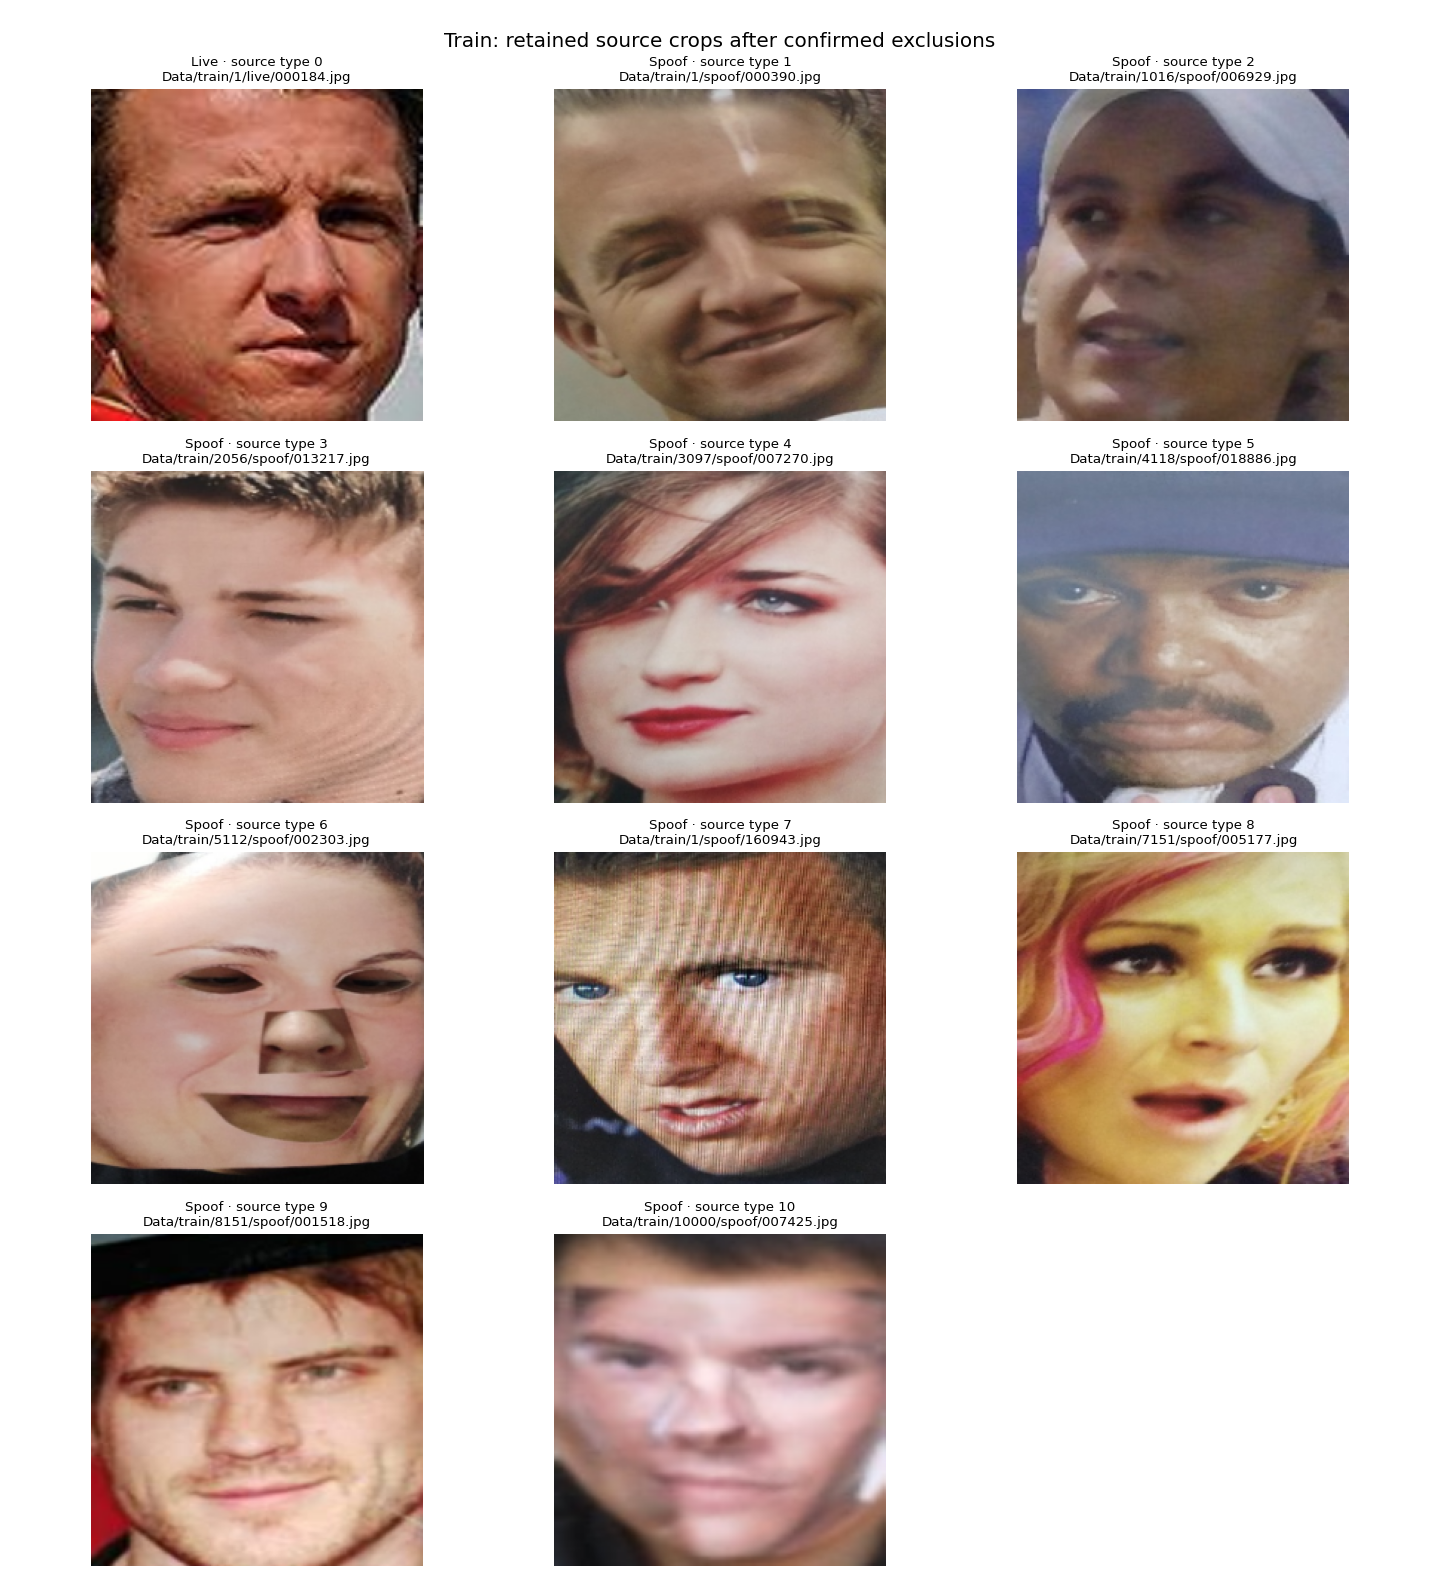

In [ ]:
if ACTION == "inspect":
    preview_name = preview_root + "/train.png"
    preview_bytes = verified_source(DRIVE_PROJECT, release["files"][preview_name])
else:
    preview_bytes = (output / "train.png").read_bytes()
with Image.open(io.BytesIO(preview_bytes)) as preview_image:
    display(preview_image)

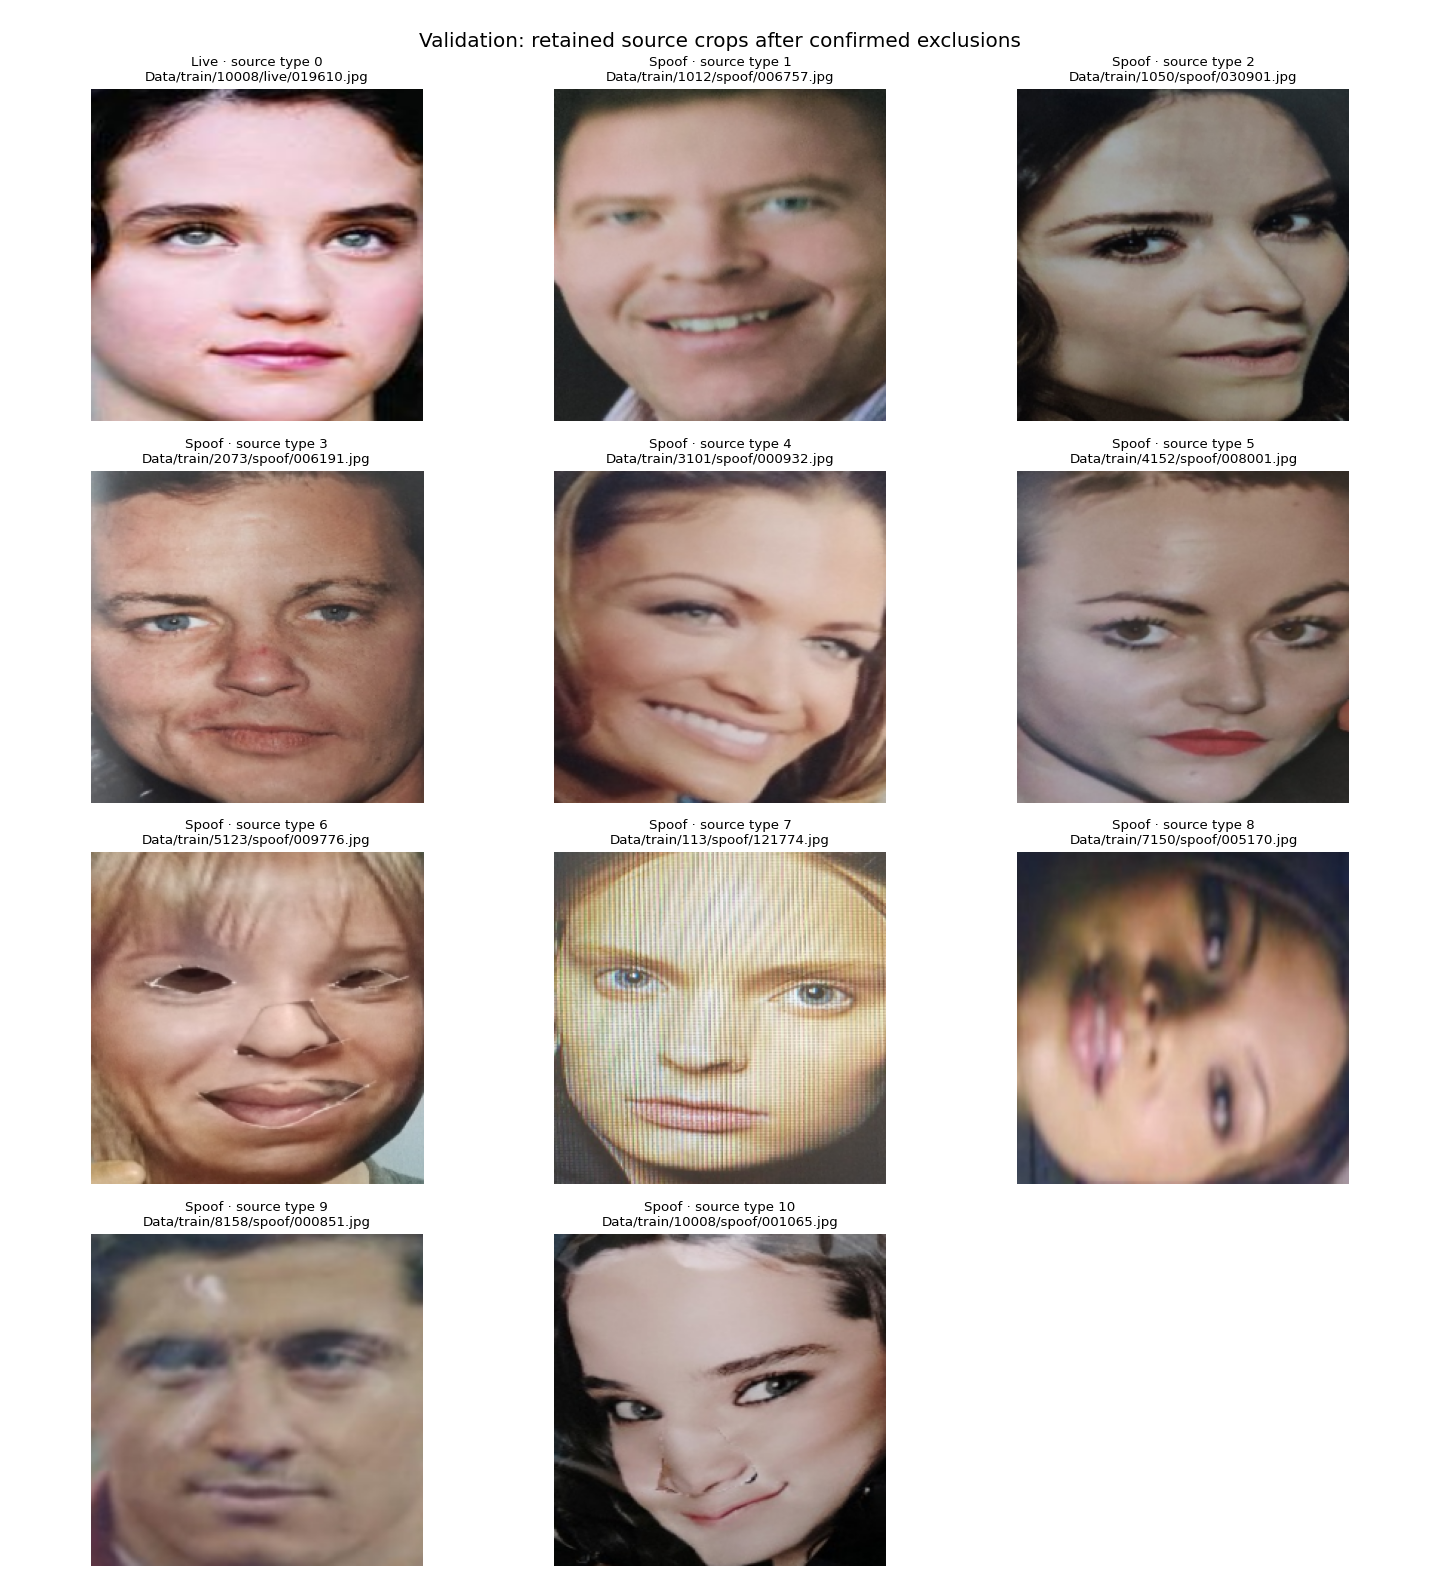

In [ ]:
if ACTION == "inspect":
    preview_name = preview_root + "/validation.png"
    preview_bytes = verified_source(DRIVE_PROJECT, release["files"][preview_name])
else:
    preview_bytes = (output / "validation.png").read_bytes()
with Image.open(io.BytesIO(preview_bytes)) as preview_image:
    display(preview_image)

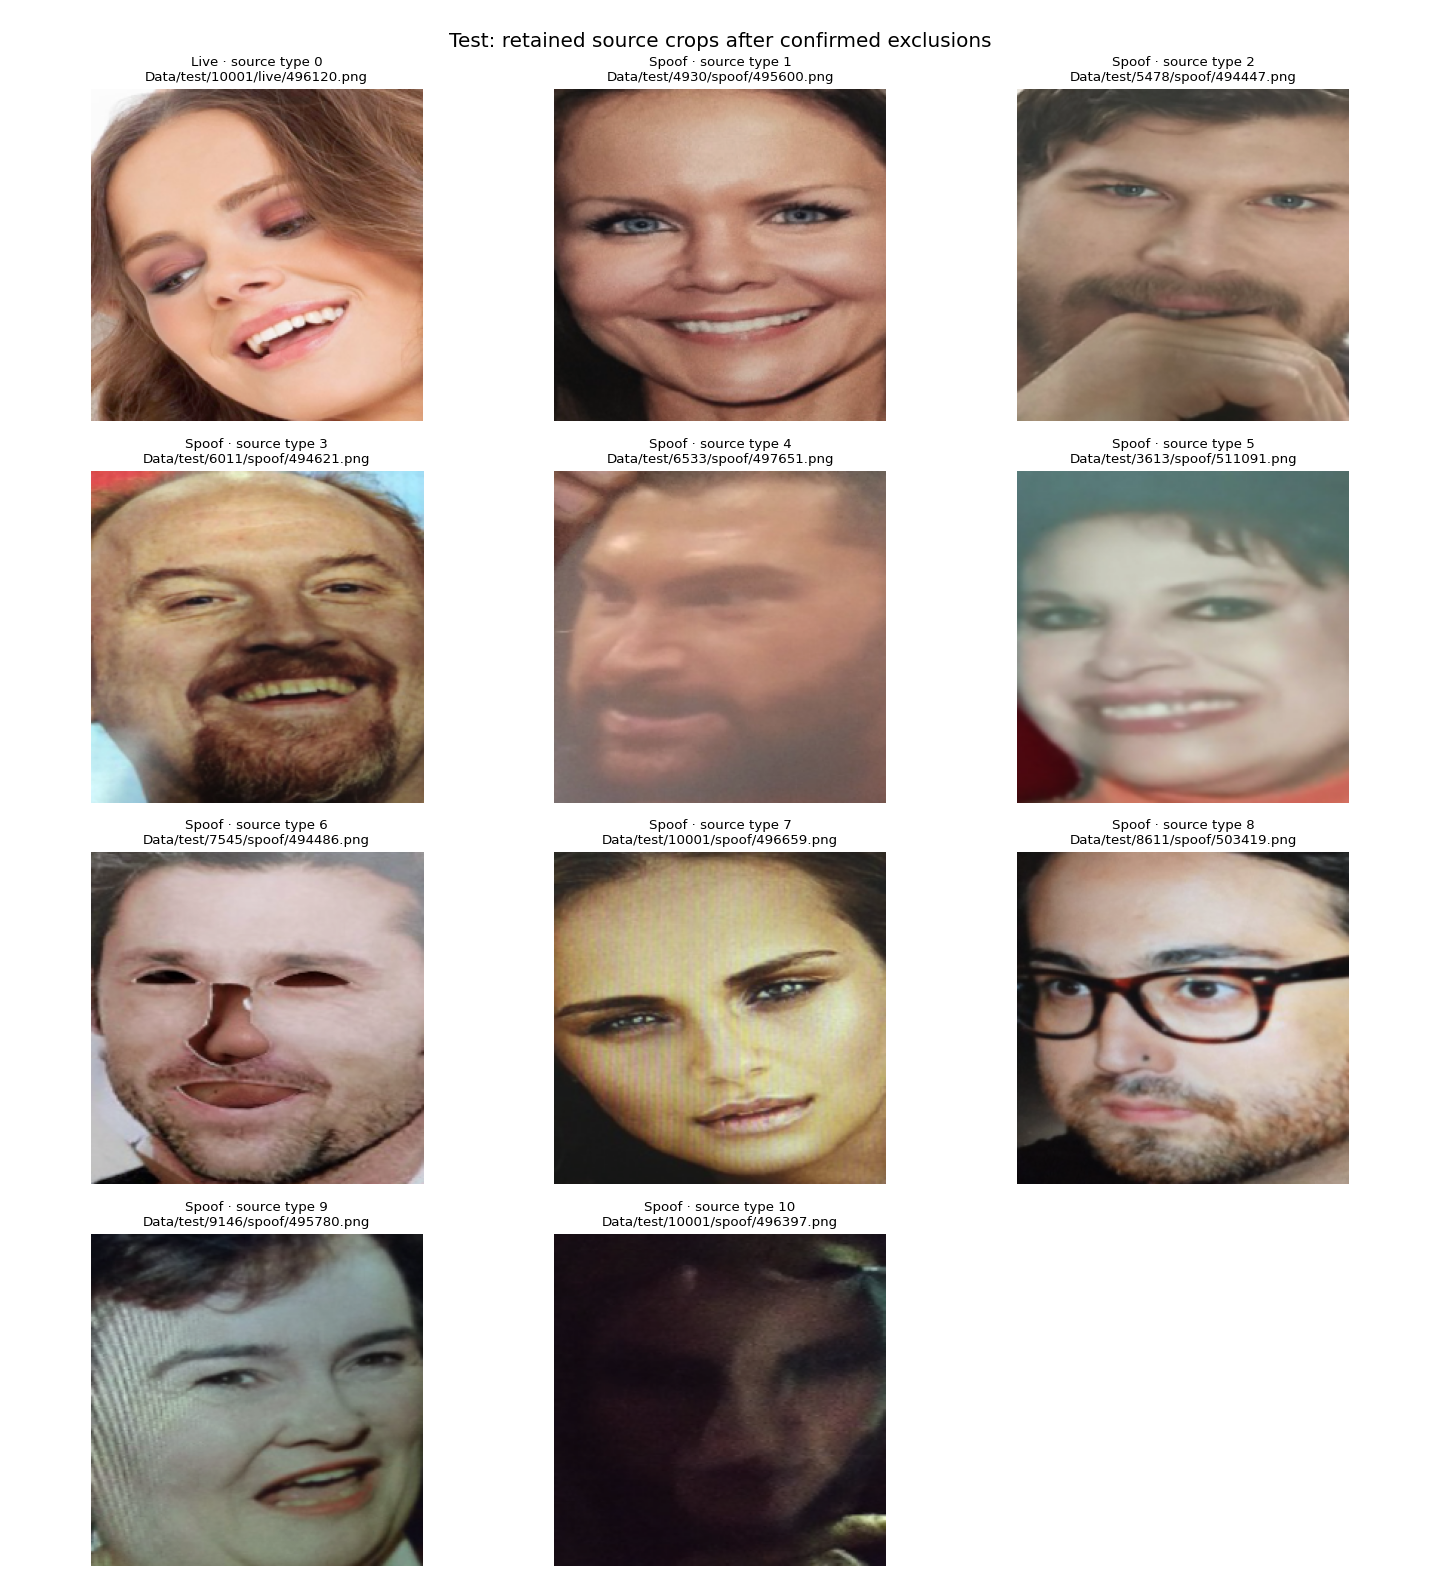

In [ ]:
if ACTION == "inspect":
    preview_name = preview_root + "/test.png"
    preview_bytes = verified_source(DRIVE_PROJECT, release["files"][preview_name])
else:
    preview_bytes = (output / "test.png").read_bytes()
with Image.open(io.BytesIO(preview_bytes)) as preview_image:
    display(preview_image)

### 8.1 Crop review

A usable crop must show the intended subject with enough detail. For example, a supplied box around a background picture selects the wrong face even if it can be enlarged to 224 × 224. Valid printed/screen attacks remain in training when detection fails; the deployment rule that zero/multiple faces means uncertain is a separate decision.

The three-day [Tracker review allocation](../README.md#project-tracker) covered 353 prioritized cases. Exclusions were 243 train, 25 validation and 41 test images, without relabelling or moving splits. The [review ledger](../evidence/liveness/crop-review/filtered-view-v4-20261126/reviewed.csv) records all decisions; unseen crops are not certified by this bounded review.


## If execution stops

Inspect the failing stage log and partial summary in the new output run. A metadata mismatch requires investigation; do not regenerate a split or change the frozen exclusions to make a check pass. Colab setup requires a fresh runtime and never replaces an existing working copy. Saved inspect previews remain attributed to their producing run. Local and Colab full-audit execution are separate evidence boundaries.
